In [ ]:
import os
import pandas as pd
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib import cm
import seaborn as sns
import pandas as pd
sns.set(style='whitegrid')

dataset = 'fineweb'
scion_method = 'unconstrained_scion' # unconstrained_scion or constrained_scion or projected_scion
loss_dataset = 'val' # train or val
epochs=5100
width = 256
out_folder="out"

if scion_method=='unconstrained_scion':
    PARAMETERIZATIONS = [
        (f'{scion_method}', r'Unconstrained Scion', 'Spectral'),
    ]
elif scion_method=='constrained_scion':
    PARAMETERIZATIONS = [
        (f'{scion_method}', r'Scion', 'Spectral'),
    ]

In [ ]:
seeds = [1,
        # 2,3
            ]
alphas=[
        0.0,
        0.5,
        1.0
        ]
depths = [
    2,
    4,
    8,
    16,
    32,
]
lrs = [
    0.00390625,
    0.001953125,
    0.0009765625,
    0.00048828125,
    0.000244140625,
    0.0001220703125,
    6.103515625e-05,
]

def get_results_table(method):
    results_table = pd.DataFrame(columns=["alpha", "depth", "lr", "loss"])
    for alpha in alphas:
        for depth_idx, depth in enumerate(depths):
            for lr in lrs:
                losses = []
                for seed in seeds:
                    losses=[]
                    csv_path = os.path.join(f'depthtransfer_{dataset}/{out_folder}/{method}_out', f'hptransferdepth_alpha_skipconnection_{alpha}_spectral_sign__depth{depth}_seed{seed}_lr{lr}', 'log.csv')
                    if os.path.exists(csv_path):
                        try:
                            ckpt_df = pd.read_csv(
                                csv_path,
                                header=1,
                                skip_blank_lines=True,
                                encoding="utf-8"
                            )
                        except pd.errors.EmptyDataError:
                            print(f"Empty CSV (no data) in {csv_path}, skipping.")
                            continue
                        except Exception as e:
                            print(f"Error reading {csv_path}: {e}")
                            continue

                        # losses.append(ckpt_df[f'{loss_dataset}/loss'].mean())
                        # losses.append(ckpt_df[f'{loss_dataset}/loss'].min())
                        losses.append(ckpt_df[f'{loss_dataset}/loss'].values[-1])
                        # losses.append(ckpt_df[f'{loss_dataset}/loss'].ewm(alpha=0.8).mean().values[-1])

                    else:
                        print(f'Missing {csv_path}')
                        continue
                
                if len(losses)==0:
                    continue

                if len(seeds)>1:
                    loss = np.mean(losses)
                else:
                    loss = losses[0]

                results_table.loc[-1,] = [alpha,depth,lr,loss]
                results_table.index = results_table.index +1
                results_table = results_table.sort_index()

    return results_table
            
scion_results_table = get_results_table("constrained_scion")
uscion_results_table = get_results_table("unconstrained_scion")

In [3]:
scion_best = scion_results_table.loc[
    scion_results_table.groupby(["alpha", "depth"])["loss"].idxmin(),
    ["alpha", "depth", "lr", "loss"]
]

scion_best_lrs = scion_best.pivot(index="alpha", columns="depth", values="lr")
scion_best_losses = scion_best.pivot(index="alpha", columns="depth", values="loss")

uscion_best = uscion_results_table.loc[
    uscion_results_table.groupby(["alpha", "depth"])["loss"].idxmin(),
    ["alpha", "depth", "lr", "loss"]
]

uscion_best_lrs = uscion_best.pivot(index="alpha", columns="depth", values="lr")
uscion_best_losses = uscion_best.pivot(index="alpha", columns="depth", values="loss")

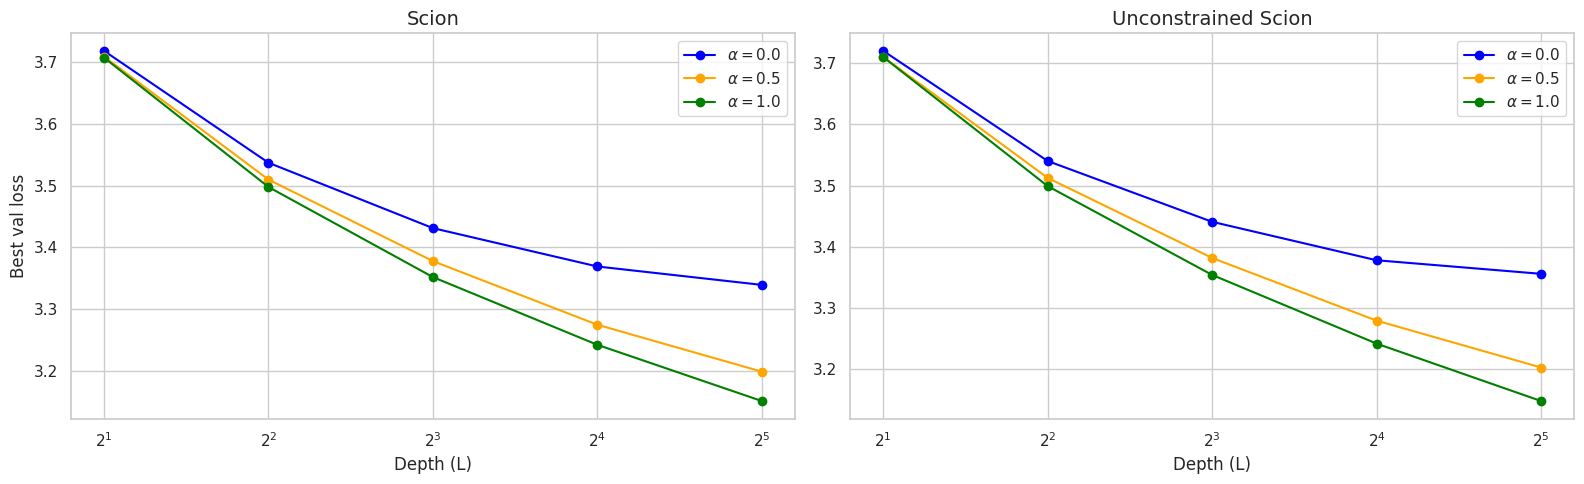

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axs = axes.ravel()

colors={
    "alpha_0.0": "blue",
    "alpha_0.5": "orange",
    "alpha_1.0": "green"
}

for i, (name, best_losses) in enumerate(zip(["Scion", "Unconstrained Scion"],[scion_best_losses, uscion_best_losses])):
    for alpha in best_losses.index:
        axs[i].plot(
            best_losses.columns,
            best_losses.loc[alpha],
            marker='o',
            label=r"$\alpha = $" + f"{alpha}",
            color=colors[f"alpha_{alpha}"]
        )

    axs[i].set_xscale('log', base=2)
    axs[i].set_xlabel("Depth (L)")
    if i ==0:
        axs[i].set_ylabel(f"Best {loss_dataset} loss")
    axs[i].set_title(f"{name}", fontsize=14)
    axs[i].legend()
    axs[i].grid(True)

plt.tight_layout()
# plt.savefig(f"best_{loss_dataset}_loss_per_depth_for_all_alphas_scion_and_uscion.pdf")
# plt.show()